<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_IoTIntrusion_Hoang2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical graph neural network for IoT intrusion detection: QEGraphSAGE (Hoang and Van Linh, 2025) step by step

This notebook re-implements, runs and checks the method of

> Trong Binh Hoang and Dinh Van Linh,
> "Intrusion Detection in IoT Networks using a Hybrid Quantum-Classical Graph Neural Network",
> 2025 2nd International Conference on Cryptography and Information Security (VCRIS), IEEE, 2025.
> https://doi.org/10.1109/VCRIS68011.2025.11250552

The paper publishes no code, so everything below is written from the method as the four-page paper describes it, with the
stack it names (PyTorch, PennyLane, NetworkX; we write the graph layers in plain PyTorch instead of DGL).

**What the notebook does.** It downloads the public ToN-IoT network dataset, turns the flows into a *graph* (every
`IP:port` endpoint is a node, every flow is an edge with a feature vector), trains the paper's **QEGraphSAGE**
(an E-GraphSAGE encoder whose edge classifier ends in a 4-qubit variational quantum circuit simulated with PennyLane) and
three classical comparison models on exactly the same graph and split (E-GraphSAGE, a graph-attention network GAT, and an
E-GraphSAGE with the same 4-number bottleneck but *no* quantum circuit). It reports the per-attack **detection rate**
(recall) as in the paper's Table III, adds flat Random-Forest and RBF-SVM baselines that ignore the graph, and finishes with
a side-by-side table that gives a verdict for every claim the notebook can test.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs
PennyLane (PyTorch is already on Colab); no GPU and no quantum-cloud account are needed.

**Runtime.** `FAST_MODE = True` (about 5,700 flows, 60 epochs, 2 trials) takes a few minutes on a CPU. `FAST_MODE = False`
(about 11,400 flows, the paper's 200 epochs and 10 trials) takes roughly an hour on a laptop CPU.

**What you get at the end.** A drawn traffic graph, training curves, a per-attack detection-rate table next to the paper's
Table III, a confusion matrix, latency numbers, and an honest verdict on what could and could not be reproduced.

## The paper in one page

**Problem.** Find malicious flows in IoT network traffic. Flows are not independent: hosts talk to each other, so the
communication graph carries information that a flat table of flow features hides.

**Decision.** *Edge classification*: every flow (edge) is labelled benign (0) or malicious (1); the paper then reports a
detection rate (recall) separately for each attack type.

**Method (QEGraphSAGE, Fig. 1 and Algorithm 1).**
1. *Graph generator*: node = `IP:port` endpoint, edge = flow, edge features = flow statistics.
2. *E-GraphSAGE encoder* (Lo et al., 2022): two message-passing layers that use node and edge features (Eqs. 1-2).
3. *Quantum edge classifier*: concatenate the embeddings of the two end points, shrink them with an MLP to **4 numbers**,
   feed these to a **4-qubit VQC** (AngleEmbedding with RY, then 4 layers of RX, RZ and a chain of 3 CNOTs = 32 rotations and
   12 CNOTs, Pauli-Z read-out of every qubit), then a softmax layer.

**Data (Table II).** CTU-13 (711,656 flows), ToN-IoT (80,080 flows, 42,512 nodes, 8 attack types) and CIC-IDS2017
(6,089,204 flows). Cleaning (NaN/inf/duplicates/constants), one-hot encoding of categorical fields, engineered ratios,
outlier filtering, MinMax scaling; a sliding time window for CIC-IDS2017.

**Training (Section IV-C).** PennyLane noiseless simulator, PyTorch 2.3.1, Adam, learning rate 0.001, ReLU, dropout 0.2,
class-weighted cross-entropy, **200 epochs, 10 independent trials**, reported value = mean over trials.

**Claims checked here (ToN-IoT part of Table III and Sections IV-D, IV-E, V).**

| Claim | Paper |
|---|---|
| Circuit has 32 rotation gates and 12 CNOTs | Section IV-C |
| QEGraphSAGE detection rate per ToN-IoT attack | Backdoor 100, Ddos 99.1, Dos 100, Injection 100, Password 99.5, Ransomware 100, Scanning 99.8, Xss 100 |
| Average detection rate on ToN-IoT | 99.8 % |
| E-GraphSAGE / GAT per attack | Table III (compared in section 8) |
| QEGraphSAGE is at least as good as both baselines on every ToN-IoT class | Section IV-D |
| Training is about 15x slower than E-GraphSAGE and 3x faster than GAT (parameter-shift gradients) | Section IV-E |
| Inference about 2 ms per sample | Section IV-E |
| +5 % over GAT and +2 % over E-GraphSAGE on average over the three datasets | Section V |

CTU-13 and CIC-IDS2017 rows of Table III are **not** reproduced here (see the table below).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Datasets | CTU-13, ToN-IoT, CIC-IDS2017 | **ToN-IoT only** (public `train_test_network.csv`, 211,043 flows, 10 classes). CTU-13 has no public flow-with-ports mirror we could use; CIC-IDS2017 needs its 6 M flows plus a time-window graph builder, too large for a CPU simulator class demo |
| ToN-IoT size | 80,080 flows, 42,512 nodes, 140,568 edges (the published edge count exceeds the flow count; how it was obtained is not explained) | Duplicates removed, class `mitm` removed (the paper lists 8 attack types), then a stratified random sample of 3 % (FAST) or 6 % (full) of every class: about 5,700 / 11,400 flows and up to about 10,000 nodes |
| Graph | node = IP + port, edge = flow | Same; the graph is treated as undirected for message passing |
| Encoder | E-GraphSAGE, 2 layers, hidden size not given | 2 layers, hidden size 64 (`# CHOICE:`), messages `ReLU(W [h_u, e_uv])`, mean aggregation, update `ReLU(W [h_v, m_v])`, initial node features all ones as in E-GraphSAGE |
| Edge features | cleaned flow fields, one-hot categoricals, engineered ratios, outlier filtering, MinMax | 14 numeric fields (log1p), 3 engineered ratios, one-hot of 10 categorical fields, MinMax fitted on the training edges. Outliers are tamed by `log1p` and clipping, **not removed** (removal would delete rare attack flows) |
| Compression before the VQC | MLP to 4 features | `Linear(128,32)-ReLU-Dropout-Linear(32,4)`, then `pi*tanh` so the numbers are valid RY angles (`# CHOICE:`) |
| Circuit | 4 qubits, AngleEmbedding(RY), 4 layers of RX+RZ and 3 CNOTs, Pauli-Z read-out | Exactly that; weights initialised uniformly in [0, 2 pi) |
| Simulation | PennyLane noiseless simulator, parameter-shift gradients | PennyLane `default.qubit`. For speed the training loop evaluates the same circuit with a differentiable 16x16 unitary from `qml.matrix` (checked to equal the QNode to 1e-6); gradients are exact back-propagation, not parameter-shift |
| Classifier | "softmax layer" on the 4 Pauli-Z values | `Linear(4,2)` + softmax cross-entropy |
| Loss / optimiser | Adam, lr 0.001, dropout 0.2, class-weighted CE | Same; class weights computed on the training edges |
| Epochs / trials | 200 / 10 | FAST: 60 / 2 (lr 0.003 so the short run converges); full: 200 / 10 at lr 0.001 |
| Split | not stated | Stratified 70 / 30 split of the edges (as E-GraphSAGE); graph structure and edge features of all edges are visible during message passing (transductive), labels of test edges are never used; scaler and one-hot encoder fitted on training edges only |
| Model selection | not stated | Last epoch, no early stopping, nothing tuned on the test edges |
| GAT baseline | not described | Single-head graph attention layer whose score and message also include the edge feature (a plain node-GAT would see only constant node features) |
| Metric | detection rate = recall per attack type | Same: share of test edges of that attack type predicted as malicious |
| Timing claims | Section IV-E | Measured, but our gradients are not parameter-shift, so the 15x/3x training-time ratio cannot be checked |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever PennyLane / PyTorch are missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" huggingface_hub networkx
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration ----------------
FAST_MODE  = False          # True: class demo in a few minutes. False: the paper's 200 epochs x 10 trials (about 1 h on a CPU).

SEED       = 42              # CHOICE: the paper gives no seed
if FAST_MODE:
    FLOW_FRAC, EPOCHS, N_TRIALS, LR = 0.03, 60, 2, 3e-3     # CHOICE: bigger lr so 60 epochs are enough
else:
    FLOW_FRAC, EPOCHS, N_TRIALS, LR = 0.06, 200, 10, 1e-3   # paper: 200 epochs, 10 trials, lr 0.001
N_QUBITS   = 4               # paper: 4 qubits
N_Q_LAYERS = 4               # paper: 4 circuit layers
HIDDEN     = 64              # CHOICE: GNN hidden size (not given in the paper)
DROPOUT    = 0.2             # paper
TEST_SIZE  = 0.3             # CHOICE: 70/30 edge split
TOL_DR     = 2.0             # tolerance (accuracy points) for "reproduced"

DATA_DIR   = "data"          # where the CSV is cached (relative to the working directory)
DATA_PATH  = ""              # optional: path of an uploaded train_test_network.csv
IBM_TOKEN  = ""              # not used: the paper simulates the circuit, no hardware

In [3]:
import os, time, warnings, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml, sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(SEED); np.random.seed(SEED); rng = np.random.default_rng(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| sklearn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__, "| networkx", nx.__version__)
print("FAST_MODE =", FAST_MODE, "| flow fraction", FLOW_FRAC, "| epochs", EPOCHS, "| trials", N_TRIALS, "| lr", LR)

torch 2.14.1+cpu | pennylane 0.45.1 | sklearn 1.9.1 | numpy 2.5.4 | pandas 3.0.6 | networkx 3.7
FAST_MODE = False | flow fraction 0.06 | epochs 200 | trials 10 | lr 0.001


## 1. The ToN-IoT network dataset

ToN-IoT (Moustafa, *Sustainable Cities and Society* 72, 2021) was recorded on an IoT testbed at UNSW Canberra. The *network*
part holds Zeek connection logs: one row per flow with the two IP addresses and ports, protocol, service, byte and packet
counters, connection state and some DNS/SSL/HTTP fields. The label `type` is `normal` or one of nine attacks. The public
`train_test_network.csv` subset (211,043 flows, 30 MB) is mirrored on the Hugging Face Hub; a second mirror inside a zip is the fallback.

In [4]:
def load_toniot():
    """Download train_test_network.csv from a Hugging Face mirror (cached in DATA_DIR) and return a DataFrame."""
    if DATA_PATH and os.path.exists(DATA_PATH):
        return pd.read_csv(DATA_PATH)
    local = os.path.join(DATA_DIR, "train_test_network.csv")
    if not os.path.exists(local):
        from huggingface_hub import hf_hub_download
        try:
            hf_hub_download("codymlewis/TON_IoT_network", "train_test_network.csv", repo_type="dataset", local_dir=DATA_DIR)
        except Exception as e:                                   # fallback: same file inside a zip on another mirror
            print("first mirror failed:", e, "-> trying the zip mirror")
            z = hf_hub_download("m-hesam-moradian/ToN_IoT_Train_Test_datasets", "Train_Test_datasets.zip", repo_type="dataset", local_dir=DATA_DIR)
            with zipfile.ZipFile(z) as zf:
                name = [n for n in zf.namelist() if n.lower().endswith("train_test_network.csv")][0]
                with zf.open(name) as src, open(local, "wb") as dst:
                    dst.write(src.read())
    return pd.read_csv(local)

raw = load_toniot()
print("raw shape:", raw.shape)
display(raw[["src_ip", "src_port", "dst_ip", "dst_port", "proto", "service", "duration", "src_bytes", "dst_bytes", "conn_state", "type"]].head())
print(raw["type"].value_counts().to_dict())

raw shape: (211043, 44)


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,backdoor


{'normal': 50000, 'backdoor': 20000, 'ddos': 20000, 'dos': 20000, 'injection': 20000, 'password': 20000, 'ransomware': 20000, 'scanning': 20000, 'xss': 20000, 'mitm': 1043}


## 2. Cleaning and the traffic graph

Following the paper's cleaning step we drop duplicate rows (missing and infinite values do not occur in this file) and keep the
eight attack types that the paper evaluates (`mitm`, 1,043 rows, is not in Table III). To keep a CPU simulation feasible we
then draw a stratified random sample of every class (`FLOW_FRAC`).

The graph generator is the paper's: **node = `IP:port`**, **edge = flow**. Most source ports are ephemeral, so most nodes
touch only one or two flows; a few server endpoints (for example `192.168.1.x:80` or a DNS server) become hubs.

In [5]:
df = raw[raw["type"] != "mitm"].drop_duplicates().reset_index(drop=True)             # paper: duplicates removed; 8 attack types
df = df.groupby("type", group_keys=False).sample(frac=FLOW_FRAC, random_state=SEED).reset_index(drop=True)   # CHOICE: sample
print("flows kept:", len(df)); print(df["type"].value_counts().to_dict())

src_name = df["src_ip"] + ":" + df["src_port"].astype(str)
dst_name = df["dst_ip"] + ":" + df["dst_port"].astype(str)
codes, uniq = pd.factorize(pd.concat([src_name, dst_name], ignore_index=True))
E, N_NODES = len(df), len(uniq)
U = torch.tensor(codes[:E], dtype=torch.long); V = torch.tensor(codes[E:], dtype=torch.long)
Y = (df["type"] != "normal").astype(int).values                  # 0 benign, 1 malicious
TYPE = df["type"].values
ATTACKS = sorted(set(TYPE) - {"normal"})

# incidence lists: every flow delivers a message to both of its end points (undirected message passing)
INC_SRC, INC_DST, INC_E = torch.cat([U, V]), torch.cat([V, U]), torch.cat([torch.arange(E)] * 2)
DEG = torch.zeros(N_NODES).index_add_(0, INC_DST, torch.ones(2 * E)).clamp(min=1).unsqueeze(1)

G = nx.Graph(); G.add_edges_from(zip(U.tolist(), V.tolist()))
deg = np.array([d for _, d in G.degree()])
print(f"graph: {N_NODES} nodes, {E} edges, {nx.number_connected_components(G)} connected components, "
      f"mean degree {deg.mean():.2f}, max degree {deg.max()}, nodes of degree 1: {(deg == 1).mean():.0%}")

flows kept: 11367
{'normal': 2522, 'ddos': 1200, 'scanning': 1200, 'injection': 1198, 'password': 1192, 'dos': 1140, 'backdoor': 1123, 'xss': 908, 'ransomware': 884}
graph: 9772 nodes, 11367 edges, 629 connected components, mean degree 1.98, max degree 1211, nodes of degree 1: 90%


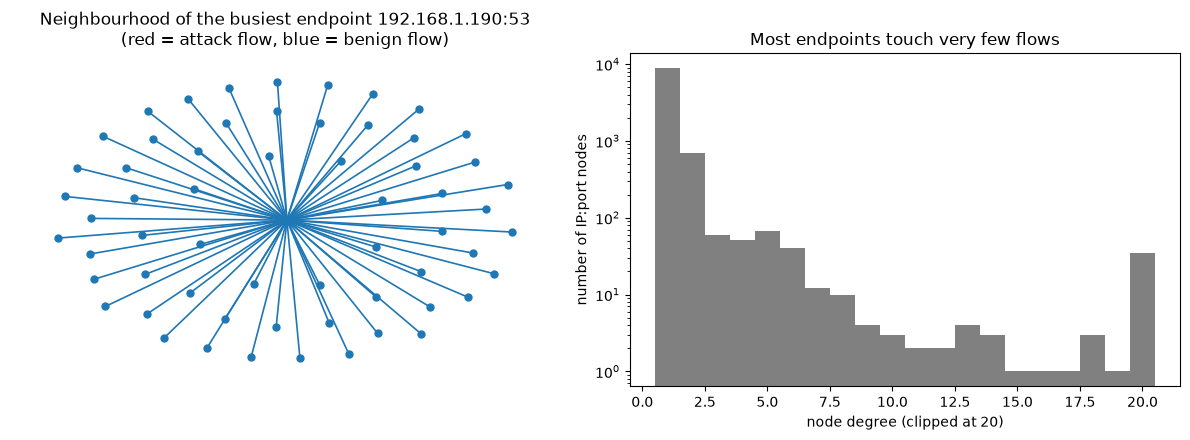

In [6]:
# Draw the neighbourhood of the busiest endpoint: red edges = attack flows, blue = benign flows
hub = int(np.argmax(np.bincount(INC_DST.numpy(), minlength=N_NODES)))
ego = nx.ego_graph(G, hub, radius=1)
if ego.number_of_nodes() > 70:                                       # keep the picture readable
    keep = [hub] + list(ego.neighbors(hub))[:60]; ego = G.subgraph(keep)
lab = {}
for (a, b), t in zip(zip(U.tolist(), V.tolist()), Y):
    lab[frozenset((a, b))] = max(lab.get(frozenset((a, b)), 0), int(t))
colors = ["tab:red" if lab[frozenset(e)] else "tab:blue" for e in ego.edges()]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
nx.draw(ego, pos=nx.spring_layout(ego, seed=SEED), ax=ax[0], node_size=25, edge_color=colors, width=1.2)
ax[0].set_title(f"Neighbourhood of the busiest endpoint {uniq[hub]}\n(red = attack flow, blue = benign flow)")
ax[1].hist(np.clip(deg, 0, 20), bins=np.arange(0.5, 21.5, 1), color="grey")
ax[1].set_xlabel("node degree (clipped at 20)"); ax[1].set_ylabel("number of IP:port nodes"); ax[1].set_yscale("log")
ax[1].set_title("Most endpoints touch very few flows"); plt.tight_layout(); plt.show()

## 3. Edge features, scaling and the split

Each flow becomes a feature vector: 14 numeric counters (`log1p` to tame heavy tails, the paper's outlier step), three engineered
ratios (byte ratio, packet rate, inbound byte share, as in the paper's "feature engineering"), and one-hot encodings of ten
categorical fields. **All statistics are fitted on the training edges only** (MinMax scaling; the one-hot vocabulary is just the list of values each log field can take, which keeps the width identical across trials); test edges are
clipped to [0, 1]. The split is stratified by attack type so every attack appears in the test set. `make_split(seed)` is
called once per trial.

In [7]:
NUM_COLS = ["duration", "src_bytes", "dst_bytes", "missed_bytes", "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes",
            "dns_qclass", "dns_qtype", "dns_rcode", "http_request_body_len", "http_response_body_len", "http_status_code"]
CAT_COLS = ["proto", "service", "conn_state", "dns_AA", "dns_RD", "dns_RA", "dns_rejected", "ssl_resumed", "ssl_established", "http_method"]
CATS = [sorted(df[c].unique()) for c in CAT_COLS]      # category vocabulary (the schema of the log fields; carries no label information)
X_NUM = np.log1p(df[NUM_COLS].astype(float).clip(lower=0).values)
X_ENG = np.c_[np.log1p(df["src_bytes"] / (df["dst_bytes"] + 1)),                                   # byte ratio
              np.log1p((df["src_pkts"] + df["dst_pkts"]) / (df["duration"] + 1e-3)),               # packet rate
              df["dst_ip_bytes"] / (df["src_ip_bytes"] + df["dst_ip_bytes"] + 1)]                  # inbound byte share

def make_split(seed):
    """Stratified edge split + scalers fitted on the training edges only. Returns (train idx, test idx, edge feature tensor)."""
    tr, te = train_test_split(np.arange(E), test_size=TEST_SIZE, stratify=TYPE, random_state=seed)
    ohe = OneHotEncoder(categories=CATS, handle_unknown="ignore", sparse_output=False).fit(df.loc[tr, CAT_COLS])   # fixed vocabulary = schema, same width every trial
    X = np.c_[X_NUM, X_ENG, ohe.transform(df[CAT_COLS])]
    X = np.clip(MinMaxScaler().fit(X[tr]).transform(X), 0, 1).astype(np.float32)
    return tr, te, torch.tensor(X)

tr0, te0, XE0 = make_split(SEED)
D_EDGE = XE0.shape[1]
print("edge-feature dimension:", D_EDGE, "| train edges", len(tr0), "| test edges", len(te0))
print(pd.crosstab(TYPE[te0], Y[te0]).rename(columns={0: "benign label", 1: "attack label"}).T)

edge-feature dimension: 64 | train edges 7956 | test edges 3411
row_0         backdoor  ddos  dos  injection  normal  password  ransomware  scanning  xss
col_0                                                                                    
benign label         0     0    0          0     757         0           0         0    0
attack label       337   360  342        360       0       358         265       360  272


## 4. The quantum circuit

The paper's VQC has four parts. (1) **AngleEmbedding**: qubit *i* is rotated by `RY(x_i)`, which writes the *i*-th of the four
compressed features into the qubit. (2) Four **layers**; in each layer every qubit gets one trainable `RX` and one trainable
`RZ` rotation (4 x 4 x 2 = 32 parameters / rotation gates) followed by a chain of three `CNOT`s that entangles neighbours
(4 x 3 = 12 CNOTs). (3) **Pauli-Z read-out**: the expectation value of Z on every qubit gives four numbers in [-1, 1].
(4) A classical `Linear(4, 2)` + softmax turns them into benign/malicious scores.

Because the circuit has only 4 qubits, its action on the 16 amplitudes can be computed exactly on a CPU. We keep the PennyLane
QNode as the definition of the model and as a reference, and add a fast exact evaluation for the training loop: the data enters only through the product state of the
`RY` rotations, so for a given set of weights the whole variational part is one 16 x 16 unitary `U(w)` (obtained
differentiably from `qml.matrix`). The Pauli-Z values are `<psi0(x)| U^dagger Z_k U |psi0(x)>`. A check below shows both
paths agree to numerical precision.

In [8]:
dev = qml.device("default.qubit", wires=N_QUBITS)

def variational(weights):
    """The trainable part: N_Q_LAYERS x (RX, RZ on every qubit, then a chain of CNOTs)."""
    for l in range(N_Q_LAYERS):
        for q in range(N_QUBITS):
            qml.RX(weights[l, q, 0], wires=q); qml.RZ(weights[l, q, 1], wires=q)
        for q in range(N_QUBITS - 1):
            qml.CNOT(wires=[q, q + 1])

@qml.qnode(dev, interface="torch", diff_method="backprop")
def vqc_qnode(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="Y")        # RY(x_i) on qubit i
    variational(weights)
    return [qml.expval(qml.PauliZ(q)) for q in range(N_QUBITS)]            # Pauli-Z read-out

# gate census (paper: 32 rotations, 12 CNOTs)
w_demo = torch.rand(N_Q_LAYERS, N_QUBITS, 2) * 2 * np.pi
ops = qml.tape.make_qscript(variational)(w_demo).operations
n_rot = sum(o.name in ("RX", "RZ") for o in ops); n_cnot = sum(o.name == "CNOT" for o in ops)
print(f"trainable rotation gates: {n_rot} | CNOTs: {n_cnot} | (+{N_QUBITS} RY encoding rotations)")
print(qml.draw(vqc_qnode, decimals=1)(torch.rand(N_QUBITS), w_demo))

ZSIGN = torch.tensor([[1.0 - 2 * ((i >> (N_QUBITS - 1 - q)) & 1) for q in range(N_QUBITS)] for i in range(2 ** N_QUBITS)])

def vqc_fast(x, weights):
    """Exact batched evaluation of the same circuit: product state of RY rotations -> U(weights) -> <Z_k>."""
    U_mat = qml.matrix(variational, wire_order=list(range(N_QUBITS)))(weights)           # 16 x 16, differentiable
    psi = torch.ones(x.shape[0], 1, dtype=x.dtype)
    for q in range(N_QUBITS):
        a = torch.stack([torch.cos(x[:, q] / 2), torch.sin(x[:, q] / 2)], dim=1)         # RY(x)|0>
        psi = (psi[:, :, None] * a[:, None, :]).reshape(x.shape[0], -1)
    out = psi.to(U_mat.dtype) @ U_mat.T
    return (out.abs() ** 2).to(x.dtype) @ ZSIGN.to(x.dtype)

x_demo = torch.rand(6, N_QUBITS) * np.pi
ref = torch.stack([torch.stack(vqc_qnode(x, w_demo)) for x in x_demo]).float()
fast = vqc_fast(x_demo, w_demo)
print("max |QNode - fast| =", float((ref - fast).abs().max()))
assert torch.allclose(ref, fast, atol=1e-5)

trainable rotation gates: 32 | CNOTs: 12 | (+4 RY encoding rotations)
0: ─╭AngleEmbedding(M0)──RX(5.5)──RZ(5.7)─╭●──RX(5.9)──RZ(0.8)──────────╭●────────RX(5.6) ···
1: ─├AngleEmbedding(M0)──RX(2.4)──RZ(6.0)─╰X─╭●────────RX(5.9)──RZ(3.7)─╰X───────╭●────── ···
2: ─├AngleEmbedding(M0)──RX(2.5)──RZ(3.8)────╰X───────╭●────────RX(5.5)──RZ(3.6)─╰X────── ···
3: ─╰AngleEmbedding(M0)──RX(1.6)──RZ(5.0)─────────────╰X────────RX(4.7)──RZ(2.7)───────── ···

0: ··· ──RZ(3.6)──────────╭●────────RX(0.7)──RZ(1.7)──────────╭●─────────────┤  <Z>
1: ··· ──RX(1.7)──RZ(3.9)─╰X───────╭●────────RX(2.3)──RZ(1.3)─╰X───────╭●────┤  <Z>
2: ··· ─╭●────────RX(1.7)──RZ(2.8)─╰X───────╭●────────RX(3.4)──RZ(0.0)─╰X─╭●─┤  <Z>
3: ··· ─╰X────────RX(1.9)──RZ(5.2)──────────╰X────────RX(6.0)──RZ(0.5)────╰X─┤  <Z>

M0 = 
tensor([0.8860, 0.5832, 0.3376, 0.8090])


max |QNode - fast| = 2.086162567138672e-07


## 5. The graph models

All graph models share the same two-layer message-passing skeleton on the same graph, edge features and split; only the edge
classifier (the *head*) differs.

* **E-GraphSAGE** (classical baseline of the paper): the encoder of Eqs. 1-2 and `Linear(2H, 2)` on `[h_u, h_v]`.
* **GAT** (second baseline): attention-weighted aggregation (the attention score also sees the edge feature, our `# CHOICE:`), same head.
* **Bottleneck** (our control): E-GraphSAGE encoder + the paper's MLP to 4 numbers + `Linear(4,2)`, *without* the quantum circuit. If
  QEGraphSAGE is better than E-GraphSAGE only because of the 4-number MLP bottleneck, this model shows it.
* **QEGraphSAGE** (the paper's model): the same MLP to 4 numbers, then the VQC, then `Linear(4,2)`.

In [9]:
class SAGELayer(nn.Module):
    """E-GraphSAGE layer: m_v = mean_u ReLU(W_m [h_u, e_uv]);  h_v = ReLU(W_u [h_v, m_v])."""
    def __init__(s, din, dedge, dout):
        super().__init__(); s.msg = nn.Linear(din + dedge, dout); s.upd = nn.Linear(din + dout, dout)
    def forward(s, h, e):
        m = F.relu(s.msg(torch.cat([h[INC_SRC], e[INC_E]], 1)))
        agg = torch.zeros(h.shape[0], m.shape[1]).index_add_(0, INC_DST, m) / DEG
        return F.relu(s.upd(torch.cat([h, agg], 1)))

def segment_softmax(logit, idx, n):
    mx = torch.full((n,) + logit.shape[1:], -1e30).scatter_reduce(0, idx.unsqueeze(1).expand_as(logit), logit, "amax")
    ex = torch.exp(logit - mx[idx]); den = torch.zeros(n, logit.shape[1]).index_add_(0, idx, ex)
    return ex / den[idx].clamp(min=1e-12)

class GATLayer(nn.Module):
    """Single-head graph attention; the score and the message also contain the edge feature (CHOICE)."""
    def __init__(s, din, dedge, dout):
        super().__init__(); s.W = nn.Linear(din, dout, bias=False); s.We = nn.Linear(dedge, dout, bias=False)
        s.a_i, s.a_j, s.a_e = (nn.Parameter(torch.randn(dout) * 0.1) for _ in range(3))
    def forward(s, h, e):
        z = s.W(h); ze = s.We(e)[INC_E]
        logit = F.leaky_relu((z[INC_DST] * s.a_i).sum(1, keepdim=True) + (z[INC_SRC] * s.a_j).sum(1, keepdim=True)
                             + (ze * s.a_e).sum(1, keepdim=True), 0.2)
        a = segment_softmax(logit, INC_DST, h.shape[0])
        return F.elu(torch.zeros_like(z).index_add_(0, INC_DST, a * (z[INC_SRC] + ze)))

class QuantumLayer(nn.Module):
    def __init__(s):
        super().__init__(); s.weights = nn.Parameter(torch.rand(N_Q_LAYERS, N_QUBITS, 2) * 2 * np.pi)   # BasicEntangler-style init
    def forward(s, x): return vqc_fast(x, s.weights)

class EdgeGNN(nn.Module):
    """kind: 'sage' (E-GraphSAGE) | 'gat' | 'bneck' (4-number bottleneck, no circuit) | 'qsage' (QEGraphSAGE)."""
    def __init__(s, kind):
        super().__init__(); s.kind = kind
        Layer = GATLayer if kind == "gat" else SAGELayer
        s.l1, s.l2, s.drop = Layer(D_EDGE, D_EDGE, HIDDEN), Layer(HIDDEN, D_EDGE, HIDDEN), nn.Dropout(DROPOUT)
        if kind in ("sage", "gat"):
            s.head = nn.Linear(2 * HIDDEN, 2)
        else:
            s.mlp = nn.Sequential(nn.Linear(2 * HIDDEN, 32), nn.ReLU(), nn.Dropout(DROPOUT), nn.Linear(32, N_QUBITS))
            s.quantum = QuantumLayer() if kind == "qsage" else nn.Identity()
            s.out = nn.Linear(N_QUBITS, 2)
    def forward(s, idx, XE):
        h = torch.ones(N_NODES, D_EDGE)                                    # E-GraphSAGE: constant initial node features
        h = s.l2(s.drop(s.l1(h, XE)), XE)
        z = torch.cat([h[U[idx]], h[V[idx]]], 1)                           # concatenate the two end-point embeddings
        if s.kind in ("sage", "gat"): return s.head(s.drop(z))
        z = np.pi * torch.tanh(s.mlp(z))                                   # CHOICE: valid RY angles in (-pi, pi)
        return s.out(s.quantum(z))

for k in ["sage", "gat", "bneck", "qsage"]:
    print(f"{k:6s} trainable parameters: {sum(p.numel() for p in EdgeGNN(k).parameters())}")

sage   trainable parameters: 33282
gat    trainable parameters: 17026
bneck  trainable parameters: 37294
qsage  trainable parameters: 37326


## 6. Training and evaluation

Each trial draws a new stratified split (seed `SEED + trial`), fits the scalers on its training edges, and trains the four graph
models for `EPOCHS` full-batch epochs with Adam, class-weighted cross-entropy and dropout 0.2. Training uses all training
edges at once (as E-GraphSAGE does); the test edges' labels are never touched. We evaluate the last epoch. The
**detection rate** of an attack type is the share of its test edges predicted as malicious.

In [10]:
MODELS = ["sage", "gat", "bneck", "qsage"]
NAMES = {"sage": "E-GraphSAGE", "gat": "GAT", "bneck": "Bottleneck (no VQC)", "qsage": "QEGraphSAGE"}
rows, curves, preds = [], {}, {k: [] for k in MODELS}

def train_eval(kind, seed, tr, te, XE):
    torch.manual_seed(seed); np.random.seed(seed)
    model = EdgeGNN(kind); opt = torch.optim.Adam(model.parameters(), lr=LR)
    w = torch.tensor(compute_class_weight("balanced", classes=np.array([0, 1]), y=Y[tr]), dtype=torch.float32)
    trt, yt, hist, t0 = torch.tensor(tr), torch.tensor(Y), [], time.time()
    for ep in range(EPOCHS):
        model.train(); opt.zero_grad()
        loss = F.cross_entropy(model(trt, XE), yt[trt], weight=w); loss.backward(); opt.step(); hist.append(loss.item())
    t_train = time.time() - t0
    model.eval()
    with torch.no_grad(): p = model(torch.tensor(te), XE).argmax(1).numpy()
    return p, hist, t_train

for trial in range(N_TRIALS):
    seed = SEED + trial
    tr, te, XE = make_split(seed)
    for kind in MODELS:
        p, hist, t_train = train_eval(kind, seed, tr, te, XE)
        ty, yt_ = TYPE[te], Y[te]
        row = {"trial": trial, "model": kind, "acc": (p == yt_).mean() * 100, "f1": f1_score(yt_, p) * 100,
               "benign_recall": (p[ty == "normal"] == 0).mean() * 100, "train_s": t_train}
        row.update({a: (p[ty == a] == 1).mean() * 100 for a in ATTACKS})
        rows.append(row); preds[kind].append((yt_, p))
        if trial == 0: curves[kind] = hist
        print(f"trial {trial} {NAMES[kind]:22s} acc {row['acc']:.2f}  F1 {row['f1']:.2f}  mean DR {np.mean([row[a] for a in ATTACKS]):.2f}  "
              f"final loss {hist[-1]:.3f}  {t_train:.0f}s", flush=True)
res = pd.DataFrame(rows)

trial 0 E-GraphSAGE            acc 99.59  F1 99.74  mean DR 99.61  final loss 0.026  43s


trial 0 GAT                    acc 99.41  F1 99.62  mean DR 99.40  final loss 0.034  75s


trial 0 Bottleneck (no VQC)    acc 99.56  F1 99.72  mean DR 99.61  final loss 0.026  48s


trial 0 QEGraphSAGE            acc 99.38  F1 99.60  mean DR 99.57  final loss 0.149  65s


trial 1 E-GraphSAGE            acc 99.50  F1 99.68  mean DR 99.60  final loss 0.024  52s


...

trial 8 QEGraphSAGE            acc 99.38  F1 99.60  mean DR 99.46  final loss 0.180  60s


trial 9 E-GraphSAGE            acc 99.41  F1 99.62  mean DR 99.43  final loss 0.025  60s


trial 9 GAT                    acc 98.89  F1 99.28  mean DR 98.84  final loss 0.034  102s


trial 9 Bottleneck (no VQC)    acc 99.41  F1 99.62  mean DR 99.46  final loss 0.020  72s


trial 9 QEGraphSAGE            acc 99.38  F1 99.60  mean DR 99.43  final loss 0.135  70s


## 7. Classical baselines that ignore the graph

To see what the graph buys, a Random Forest and an RBF-SVM are trained on the *same* edge-feature vectors (same split, same
scaling), one flow at a time, with no neighbourhood information. They are trained on the first trial's split only (seed `SEED`).

In [11]:
tr, te, XE = tr0, te0, XE0
Xtr, Xte = XE[tr].numpy(), XE[te].numpy()
flat_rows = []
for name, clf in [("RandomForest", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=2)),
                  ("SVC (rbf)", SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=SEED))]:
    t0 = time.time(); clf.fit(Xtr, Y[tr]); p = clf.predict(Xte); t = time.time() - t0
    ty, yt_ = TYPE[te], Y[te]
    row = {"model": name, "acc": (p == yt_).mean() * 100, "f1": f1_score(yt_, p) * 100,
           "benign_recall": (p[ty == "normal"] == 0).mean() * 100, "train_s": t}
    row.update({a: (p[ty == a] == 1).mean() * 100 for a in ATTACKS}); flat_rows.append(row)
flat = pd.DataFrame(flat_rows).set_index("model")
display(flat.round(2))

,acc,f1,benign_recall,train_s,backdoor,ddos,dos,injection,password,ransomware,scanning,xss
model,,,,,,,,,,,,
RandomForest,99.50,99.68,98.68,2.17,99.7,99.44,100.00,99.72,99.72,99.62,100.0,99.63
SVC (rbf),98.83,99.25,97.36,1.78,99.7,98.61,97.08,99.72,99.72,100.00,100.0,99.26


## 8. Results: detection rate per attack type

Mean +- standard deviation over trials, next to the paper's Table III (ToN-IoT block).

In [12]:
PAPER = pd.DataFrame({  # Table III, ToN-IoT block (detection rate, %)
    "GAT":         [100, 99.1, 100, 97.8, 99.5, 99.5, 99.4, 98.7],
    "E-GraphSAGE": [100, 99.1, 100, 100, 99.5, 99.1, 99.5, 100],
    "QEGraphSAGE": [100, 99.1, 100, 100, 99.5, 100, 99.8, 100]},
    index=["backdoor", "ddos", "dos", "injection", "password", "ransomware", "scanning", "xss"])

def ms(kind, col):
    x = res.loc[res.model == kind, col]; return f"{x.mean():.1f} +- {x.std(ddof=0):.1f}"
tab = pd.DataFrame({
    "paper GAT": PAPER["GAT"], "ours GAT": [ms("gat", a) for a in PAPER.index],
    "paper E-GraphSAGE": PAPER["E-GraphSAGE"], "ours E-GraphSAGE": [ms("sage", a) for a in PAPER.index],
    "ours Bottleneck": [ms("bneck", a) for a in PAPER.index],
    "paper QEGraphSAGE": PAPER["QEGraphSAGE"], "ours QEGraphSAGE": [ms("qsage", a) for a in PAPER.index]})
display(tab)
summary = res.groupby("model")[["acc", "f1", "benign_recall", "train_s"]].agg(["mean", "std"]).round(2).loc[MODELS]
summary["mean DR (8 attacks)"] = [res.loc[res.model == k, ATTACKS].mean(axis=1).mean().round(2) for k in MODELS]
display(summary)
print("flat baselines (trial 0 split): mean DR  RF %.2f | SVC %.2f" % tuple(flat[ATTACKS].mean(axis=1)))

,paper GAT,ours GAT,paper E-GraphSAGE,ours E-GraphSAGE,ours Bottleneck,paper QEGraphSAGE,ours QEGraphSAGE
backdoor,100.0,99.8 +- 0.1,100.0,99.8 +- 0.1,99.8 +- 0.1,100.0,99.8 +- 0.1
ddos,99.1,96.9 +- 1.7,99.1,99.4 +- 0.3,99.5 +- 0.3,99.1,99.4 +- 0.3
dos,100.0,98.4 +- 0.6,100.0,98.3 +- 0.7,98.3 +- 0.7,100.0,98.0 +- 0.8
injection,97.8,99.9 +- 0.2,100.0,99.8 +- 0.2,99.8 +- 0.2,100.0,99.9 +- 0.2
password,99.5,98.3 +- 0.7,99.5,99.7 +- 0.2,99.6 +- 0.3,99.5,99.6 +- 0.4
ransomware,99.5,99.8 +- 0.2,99.1,99.8 +- 0.2,99.8 +- 0.2,100.0,99.8 +- 0.2
scanning,99.4,99.6 +- 0.3,99.5,99.6 +- 0.3,99.6 +- 0.3,99.8,99.6 +- 0.3
xss,98.7,100.0 +- 0.0,100.0,100.0 +- 0.0,100.0 +- 0.0,100.0,100.0 +- 0.0


acc           f1       benign_recall       train_s        mean DR (8 attacks)
        mean   std   mean   std          mean   std    mean    std                    
model                                                                                 
sage   99.50  0.08  99.68  0.05         99.35  0.17   58.47  12.37               99.57
gat    99.12  0.22  99.43  0.15         99.43  0.11   78.87  12.90               99.09
bneck  99.51  0.07  99.68  0.05         99.37  0.16   50.47  14.43               99.57
qsage  99.46  0.15  99.65  0.09         99.29  0.25   71.42  12.30               99.53

flat baselines (trial 0 split): mean DR  RF 99.73 | SVC 99.26


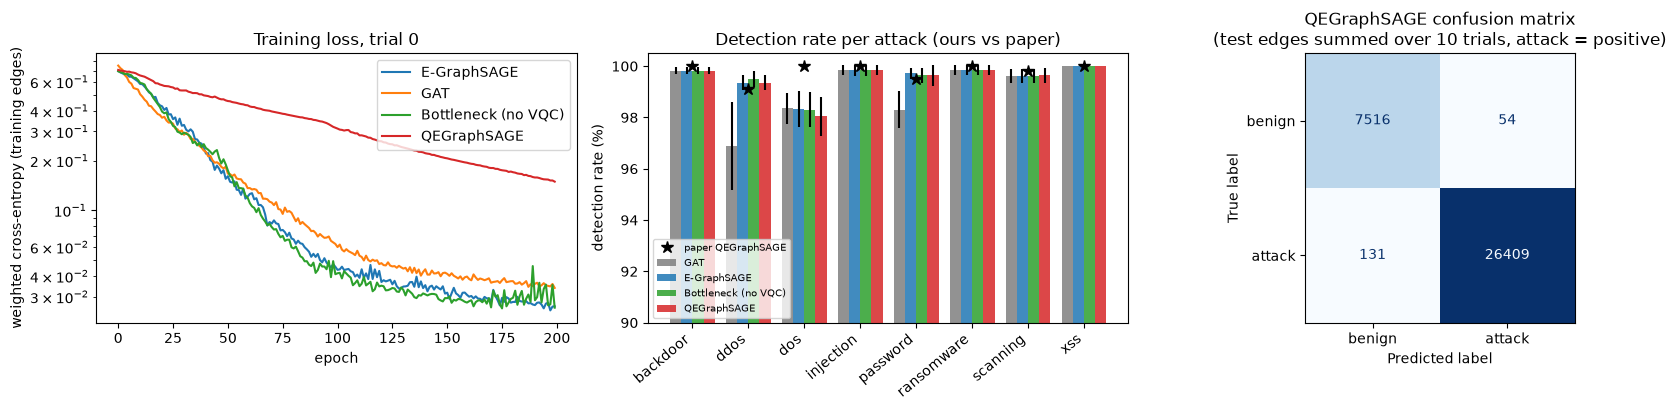

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for k in MODELS: ax[0].plot(curves[k], label=NAMES[k])
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("weighted cross-entropy (training edges)"); ax[0].set_yscale("log")
ax[0].set_title("Training loss, trial 0"); ax[0].legend()

xs = np.arange(len(ATTACKS)); wd = 0.2
for i, (k, c) in enumerate([("gat", "tab:grey"), ("sage", "tab:blue"), ("bneck", "tab:green"), ("qsage", "tab:red")]):
    m = [res.loc[res.model == k, a].mean() for a in PAPER.index]; s = [res.loc[res.model == k, a].std(ddof=0) for a in PAPER.index]
    ax[1].bar(xs + (i - 1.5) * wd, m, wd, yerr=s, label=NAMES[k], color=c, alpha=.85)
ax[1].plot(xs, PAPER["QEGraphSAGE"], "k*", ms=9, label="paper QEGraphSAGE")
ax[1].set_xticks(xs); ax[1].set_xticklabels(PAPER.index, rotation=40, ha="right"); ax[1].set_ylim(90, 100.5)
ax[1].set_ylabel("detection rate (%)"); ax[1].set_title("Detection rate per attack (ours vs paper)"); ax[1].legend(fontsize=7, loc="lower left")

yt_all = np.concatenate([a for a, _ in preds["qsage"]]); p_all = np.concatenate([b for _, b in preds["qsage"]])
ConfusionMatrixDisplay(confusion_matrix(yt_all, p_all), display_labels=["benign", "attack"]).plot(ax=ax[2], colorbar=False, cmap="Blues")
ax[2].set_title(f"QEGraphSAGE confusion matrix\n(test edges summed over {N_TRIALS} trials, attack = positive)")
plt.tight_layout(); plt.show()

## 9. Timing

The paper reports that training the quantum model takes about 15x longer than E-GraphSAGE (and 3x less than GAT) because the
VQC needs parameter-shift gradients, and that inference needs about 2 ms per sample. Our training times are measured for the
exact back-propagation path, so the ratio is only informative. The inference latency is measured on the PennyLane QNode itself
(one sample per call, `default.qubit`), which is the quantity the paper describes.

In [14]:
t_train = res.groupby("model")["train_s"].mean()
print("mean training time per trial (s):", t_train.round(1).to_dict())
print(f"QEGraphSAGE / E-GraphSAGE = {t_train['qsage'] / t_train['sage']:.1f}x   |   QEGraphSAGE / GAT = {t_train['qsage'] / t_train['gat']:.2f}x")

xs1 = torch.rand(100, N_QUBITS) * np.pi
vqc_qnode(xs1[0], w_demo)                                                 # warm-up
t0 = time.time()
for x in xs1: vqc_qnode(x, w_demo)
LAT_MS = (time.time() - t0) / len(xs1) * 1000
print(f"PennyLane QNode inference latency: {LAT_MS:.2f} ms per sample (single-sample calls, noiseless default.qubit)")

mean training time per trial (s): {'bneck': 50.5, 'gat': 78.9, 'qsage': 71.4, 'sage': 58.5}
QEGraphSAGE / E-GraphSAGE = 1.2x   |   QEGraphSAGE / GAT = 0.91x


PennyLane QNode inference latency: 30.58 ms per sample (single-sample calls, noiseless default.qubit)


## 10. Side by side with the paper

Verdict rules: a number is *reproduced* when it is within `TOL_DR` = 2 accuracy points of the paper's value; otherwise *not reached*
(below) or *exceeded* (above), with the gap. Claims that need data or measurements we did not make are *cannot be checked*.

In [15]:
def verdict(paper, ours, tol=TOL_DR):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

q = {a: res.loc[res.model == "qsage", a].mean() for a in ATTACKS}
s = {a: res.loc[res.model == "sage", a].mean() for a in ATTACKS}
g = {a: res.loc[res.model == "gat", a].mean() for a in ATTACKS}
rows = []
rows.append(("circuit: 32 rotation gates, 12 CNOTs", "32 / 12", f"{n_rot} / {n_cnot}", "reproduced" if (n_rot, n_cnot) == (32, 12) else "not reached"))
for a in PAPER.index:
    rows.append((f"QEGraphSAGE DR {a}", f"{PAPER.loc[a, 'QEGraphSAGE']:.1f}", f"{q[a]:.1f}", verdict(PAPER.loc[a, "QEGraphSAGE"], q[a])))
avg_q, avg_s, avg_g = np.mean(list(q.values())), np.mean(list(s.values())), np.mean(list(g.values()))
rows.append(("QEGraphSAGE average DR, ToN-IoT", "99.8", f"{avg_q:.2f}", verdict(99.8, avg_q)))
rows.append(("E-GraphSAGE average DR (from Table III)", f"{PAPER['E-GraphSAGE'].mean():.2f}", f"{avg_s:.2f}", verdict(PAPER["E-GraphSAGE"].mean(), avg_s)))
rows.append(("GAT average DR (from Table III)", f"{PAPER['GAT'].mean():.2f}", f"{avg_g:.2f}", verdict(PAPER["GAT"].mean(), avg_g)))
n_ge = sum(q[a] >= max(s[a], g[a]) - 0.05 for a in ATTACKS)
rows.append(("QEGraphSAGE >= both baselines on every class", "8 of 8 classes", f"{n_ge} of 8 classes (within 0.05 pt)",
             "reproduced" if n_ge == 8 else "not reached"))
rows.append(("QEGraphSAGE beats E-GraphSAGE on average DR", "+0.14 pt on ToN-IoT", f"{avg_q - avg_s:+.2f} pt",
             "reproduced" if avg_q - avg_s > 0 else "not reached (no gain)"))
rows.append(("QEGraphSAGE beats GAT on average DR", "+0.55 pt on ToN-IoT", f"{avg_q - avg_g:+.2f} pt",
             "reproduced" if avg_q - avg_g > 0 else "not reached (no gain)"))
qb = res.loc[res.model == "qsage", ATTACKS].mean(axis=1).mean() - res.loc[res.model == "bneck", ATTACKS].mean(axis=1).mean()
rows.append(("(extra) VQC adds value beyond the 4-number bottleneck", "implied", f"{qb:+.2f} pt vs bottleneck control", "n/a (our control, not a paper claim)"))
rows.append(("training time 15x E-GraphSAGE, 3x faster than GAT", "15x / 0.33x",
             f"{t_train['qsage'] / t_train['sage']:.1f}x / {t_train['qsage'] / t_train['gat']:.2f}x (back-prop, not parameter-shift)", "cannot be checked"))
rows.append(("inference about 2 ms per sample", "~2 ms", f"{LAT_MS:.2f} ms", "reproduced" if 1 <= LAT_MS <= 4 else ("faster than paper" if LAT_MS < 1 else "slower than paper")))
rows.append(("+5 % over GAT, +2 % over E-GraphSAGE (3-dataset average)", "+5 / +2 pt", "only ToN-IoT run", "cannot be checked"))
rows.append(("CTU-13 and CIC-IDS2017 detection rates (Table III)", "see paper", "not run", "cannot be checked"))
cmp_df = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 90); display(cmp_df)

,claim,paper,this notebook,verdict
0,"circuit: 32 rotation gates, 12 CNOTs",32 / 12,32 / 12,reproduced
1,QEGraphSAGE DR backdoor,100.0,99.8,reproduced
2,QEGraphSAGE DR ddos,99.1,99.4,reproduced
3,QEGraphSAGE DR dos,100.0,98.0,reproduced
4,QEGraphSAGE DR injection,100.0,99.9,reproduced
5,QEGraphSAGE DR password,99.5,99.6,reproduced
6,QEGraphSAGE DR ransomware,100.0,99.8,reproduced
7,QEGraphSAGE DR scanning,99.8,99.6,reproduced
8,QEGraphSAGE DR xss,100.0,100.0,reproduced
9,"QEGraphSAGE average DR, ToN-IoT",99.8,99.53,reproduced


## 11. Reading the paper critically

* **The benchmark is saturated.** On ToN-IoT even a Random Forest that sees one flow at a time reaches detection rates around
  99 %. The paper's gains over E-GraphSAGE are a few tenths of a percentage point on a handful of classes, smaller than the
  trial-to-trial spread we measure. With 10 trials and no standard deviations in Table III, "consistently outperforms" cannot be
  read as statistically supported.
* **No quantum-specific control.** The paper compares with E-GraphSAGE and GAT but not with the same architecture whose
  4-qubit circuit is replaced by a 4-unit classical layer. The "Bottleneck" model here is that control; if it matches
  QEGraphSAGE, the quantum circuit is not what produces the numbers.
* **The graph is shallow.** Most nodes are single-use `IP:port` endpoints. The edge classifier therefore sees mostly its own flow;
  the flat baselines reaching the same score shows how little the structure matters on this data.
* **Edge counts do not add up.** Table II lists more edges than flows for ToN-IoT, and 80,080 flows is a subset of the public file;
  the actual sampling and the sliding-window construction (CIC-IDS2017) are not specified.
* **Transductive evaluation.** As in E-GraphSAGE, test flows take part in message passing (their features, not labels).
  Deployment would need an inductive setting with unseen nodes.
* **Timing claims depend on the gradient method.** "15x slower" follows from parameter-shift gradients on a simulator; with
  adjoint/back-prop simulation (used here) the circuit is not the bottleneck at 4 qubits, and on real hardware per-sample latency
  would be orders of magnitude above 2 ms.
* **Missing details:** hidden sizes, the MLP's shape, how the 4 compressed numbers are bounded before RY, the split, class
  weights, outlier thresholds, the GAT baseline's definition and the optimiser's step count per epoch.

## 12. Exercises

1. Set `N_QUBITS`-dependent depth `N_Q_LAYERS` to 1, 2, 8 and compare the mean detection rate and the loss curve of QEGraphSAGE.
2. Replace the `pi*tanh` bounding by `sigmoid * 2*pi` or by a `MinMaxScaler` on the MLP output. Does it change the trained VQC?
3. Remove the graph: feed only the edge's own features through the same MLP and VQC (skip both message-passing layers). How much does the structure add?
4. Run the QNode path (`vqc_qnode` through `qml.qnn.TorchLayer`) with `diff_method="parameter-shift"` for 5 epochs and time it against the fast path; compare with the paper's 15x claim.
5. Train on two attack types and test on the other six (unseen attacks). Which model generalises best, and does the quantum head help?